# Lesson 1, one call at a time

Lesson 1 built a complete workflow on 569 tumours and then broke it four ways. This
notebook takes the calls it used one at a time, on eight to a hundred rows, so that
every number can be read: how a split is drawn, what a baseline is, how accuracy,
precision and recall are counted, and how a model can look excellent on data that
holds nothing to learn.

**How to use it.** Each section is one *atom*. Before each code cell that teaches
something there is a question under *Your prediction, before you run the next cell*:
answer it first, then run. The notebook `00_the_scikit_learn_api.ipynb` covers what
`fit`, `predict`, `predict_proba` and `score` do in general, and why the inputs are
NumPy arrays of shape `(m, n)`; this one assumes it.

Not examinable. The full-scale version of each atom is in lesson 1's notebooks
`02_first_ml_workflow.ipynb` and `03_how_models_mislead.ipynb`.

## Setup

In [1]:
# Everything used here ships with the course image:
# pip install numpy==1.26.4 pandas==2.1.1 scikit-learn==1.3.1 matplotlib==3.8.0

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)

## 1. `train_test_split`, and what `stratify` keeps

`train_test_split(X, y)` shuffles the rows and returns four pieces, always in the
same order: training inputs, test inputs, training labels, test labels. With
`stratify=y` it draws the test rows so that each class keeps the share it has in the
whole dataset.

*From:* lesson 1, slide *Step 3: split, before anything else* and notebook 2, section *Split before you do anything else*.

In [2]:
# Eight patients, one measurement each; two of the eight are ill (label 1).
X = np.array([[1.0], [2.0], [3.0], [4.0], [5.0], [6.0], [7.0], [8.0]])
y = np.array([0, 0, 0, 0, 0, 0, 1, 1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
print("X_train:", X_train.ravel(), "  y_train:", y_train)
print("X_test: ", X_test.ravel(), "  y_test: ", y_test)

X_train: [4. 1. 6. 5.]   y_train: [0 0 0 0]
X_test:  [7. 3. 2. 8.]   y_test:  [1 0 0 1]


### Your prediction, before you run the next cell

A quarter of the patients are ill, so a fair test set of four would hold
exactly one. Over ten different seeds, how many test sets drawn *without* `stratify`
will hold exactly one ill patient? And with `stratify=y`?

In [3]:
print("seed | ill patients in the test set: without stratify | with stratify")
for seed in range(10):
    _, _, _, plain = train_test_split(X, y, test_size=0.5, random_state=seed)
    _, _, _, strat = train_test_split(X, y, test_size=0.5, random_state=seed, stratify=y)
    print(f"{seed:4} | {plain.sum():^42} | {strat.sum():^13}")

seed | ill patients in the test set: without stratify | with stratify
   0 |                     2                      |       1      
   1 |                     2                      |       1      
   2 |                     1                      |       1      
   3 |                     2                      |       1      
   4 |                     1                      |       1      
   5 |                     1                      |       1      
   6 |                     2                      |       1      
   7 |                     1                      |       1      
   8 |                     2                      |       1      
   9 |                     1                      |       1      


**What to look at.** Without `stratify` the test set holds one or two ill patients
depending on the seed, and when it holds both, the training set has none to learn
from: the first cell above, seed 0, shows a training set of four healthy patients
(`y_train` is all zeros). With `stratify=y` every seed gives exactly one, the share of the whole dataset.
On 569 tumours the drift is smaller but still there, which is why lesson 1 always
passes `stratify=y` for a classification.

**Try changing.** give `y` four ill patients out of eight and repeat: how often does a
plain split still go wrong?

## 2. `DummyClassifier`: the score to beat, and two ways to read it

A baseline is a model that ignores the inputs. `DummyClassifier(strategy=
"most_frequent")` learns one thing in `fit`, the most common label, and predicts it for
every row. Any real model has to beat it, or it has learned nothing useful.

*From:* lesson 1, slide *Step 4: baseline first* and notebook 2, section *Establish a baseline*.

In [4]:
# The stratified split of atom 1, seed 0: three healthy and one ill patient in each half.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0, stratify=y)
print("y_train:", y_train, "  y_test:", y_test)

y_train: [1 0 0 0]   y_test: [0 1 0 0]


### Your prediction, before you run the next cell

What will the dummy predict for the four test patients, and what accuracy
will it reach?

In [5]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("what fit learned, classes_ and their shares:", dummy.classes_, dummy.class_prior_)
print("predict:      ", dummy.predict(X_test))
print("predict_proba:", dummy.predict_proba(X_test)[0], "for every row")

what fit learned, classes_ and their shares: [0 1] [0.75 0.25]
predict:       [0 0 0 0]
predict_proba: [1. 0.] for every row


**What to look at.** The dummy learned that 0 is the most frequent label, with share
0.75, and predicts 0 for all four test patients whatever their measurement. Its
`predict_proba` is `[1, 0]` on every row: it is certain, and it never names the ill
patient.

### Your prediction, before you run the next cell

`dummy.score(X_test, y_test)` and `accuracy_score(y_test,
dummy.predict(X_test))`: the same number or two different ones?

In [6]:
print("dummy.score:        ", dummy.score(X_test, y_test))
print("accuracy_score:     ", accuracy_score(y_test, dummy.predict(X_test)))
print("right answers / all:", (dummy.predict(X_test) == y_test).sum(), "/", len(y_test))

dummy.score:         0.75
accuracy_score:      0.75
right answers / all: 3 / 4


**What to look at.** **0.75** three times. `score` is accuracy for a
classifier; `accuracy_score` is the same count, called from `sklearn.metrics` with the
true labels first and the predictions second. On this data a model has to beat 0.75
before it has done anything, which is lesson 1's 62.9% on the tumours, at a smaller
scale.

**Try changing.** use `strategy="stratified"`, which answers at random in the
training proportions, and run the prediction cell a few times with different
`random_state` values.

## 3. Behind every label, a probability, and a threshold nobody chose

`predict` turns each probability into a label by comparing it with 0.5. That 0.5
is a default, not a decision anyone made about the problem. Taking the probabilities
from `predict_proba` and choosing the threshold yourself changes which patients are
flagged.

*From:* lesson 1, slides *Behind every label, a probability* and *The trade-off, drawn*; notebook 2, section *The threshold nobody chose*.

In [7]:
# Ten tumours: size in millimetres, and whether each was malignant (1) or benign (0).
size = np.array([[8.0], [10.0], [11.0], [13.0], [14.0], [15.0], [17.0], [18.0], [20.0], [23.0]])
malignant = np.array([0, 0, 0, 1, 0, 0, 1, 0, 1, 1])
model = LogisticRegression().fit(size, malignant)
p = model.predict_proba(size)[:, 1]          # column 1 = probability of class 1, malignant
print("P(malignant):", p.round(2))

P(malignant): [0.04 0.08 0.11 0.21 0.28 0.36 0.55 0.64 0.8  0.92]


### Your prediction, before you run the next cell

At the default threshold 0.5, how many of the four malignant tumours
are flagged? And if the threshold is lowered to 0.2?

In [8]:
for threshold in (0.5, 0.2):
    flagged = (p >= threshold).astype(int)
    caught = (flagged & malignant).sum()
    false_alarms = (flagged & (1 - malignant)).sum()
    print(f"threshold {threshold}: flagged {flagged}  malignant caught {caught} of 4, "
          f"benign flagged {false_alarms}")
print("predict() is the 0.5 row:", model.predict(size))

threshold 0.5: flagged [0 0 0 0 0 0 1 1 1 1]  malignant caught 3 of 4, benign flagged 1
threshold 0.2: flagged [0 0 0 1 1 1 1 1 1 1]  malignant caught 4 of 4, benign flagged 3
predict() is the 0.5 row: [0 0 0 0 0 0 1 1 1 1]


**What to look at.** At 0.5 the malignant tumour of 13 millimetres, with
probability 0.21, is missed. At 0.2 all four are caught and, as the price, three benign
tumours are flagged instead of one. Which threshold is right is a question about the
cost of each mistake, which lesson 1's slide *Which error is worse?* hands to the
people who bear it; `predict` silently answers it with 0.5.

**Try changing.** try thresholds 0.3 and 0.7, and find the highest threshold that
still catches all four malignant tumours.

## 4. The confusion matrix: where the right and wrong answers fall

Accuracy counts right answers and nothing else. The **confusion matrix** splits
them by class: one row per true class, one column per predicted class. In
scikit-learn the rows are the truth and the columns the prediction, in the order of
the labels, so for labels 0 and 1 the bottom-right cell counts the patients who are
ill *and* were flagged.

*From:* lesson 1, slide *What accuracy hides* and notebook 2, section *Accuracy is not the answer*.

In [9]:
# Ten patients: the truth (1 = malignant), and what some model predicted.
y_true = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0])
y_pred = np.array([1, 1, 1, 0, 1, 1, 0, 0, 0, 0])
print("accuracy:", accuracy_score(y_true, y_pred))

accuracy: 0.7


### Your prediction, before you run the next cell

Accuracy is 0.7, so three answers are wrong. How many of the three are
malignant tumours that were missed, and in which cell of the matrix do they go?

[[4 2]
 [1 3]]


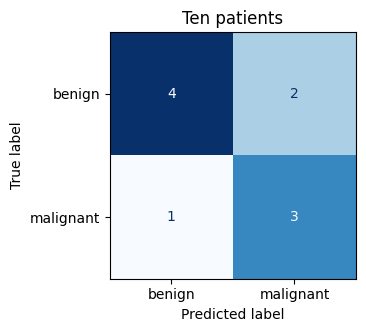

In [10]:
print(confusion_matrix(y_true, y_pred))
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["benign", "malignant"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Ten patients")
plt.show()

**What to look at.** Read it as true row, predicted column. Bottom row, the four
malignant tumours: 3 flagged, **1 missed** (true malignant, predicted benign: a *false
negative*). Top row, the six benign ones: 4 left alone, **2 flagged by mistake** (*false
positives*). Accuracy added the 3 and the 4 and stopped there, so it cannot tell a
missed tumour from a false alarm. `ConfusionMatrixDisplay.from_predictions` draws the
same table from labels; `from_estimator`, used in lesson 1, calls `predict` first.

**Try changing.** swap one false positive for a second false negative in `y_pred`:
accuracy does not move, the matrix does.

## 5. Precision and recall, counted and then printed

**Recall** is the share of the truly malignant that were flagged:
TP / (TP + FN), with true positives (TP) and false negatives (FN). **Precision** is the
share of the flagged that were truly malignant: TP / (TP + FP), with false positives
(FP). Same numerator, different denominator: recall divides by a row of the matrix,
precision by a column. `classification_report` prints both for each class.

*From:* lesson 1, slides *Precision and recall* and *Precision and recall, counted*.

### Your prediction, before you run the next cell

With the ten patients of atom 4 (TP = 3, FN = 1, FP = 2), what are recall
and precision for the malignant class?

In [11]:
tp = ((y_pred == 1) & (y_true == 1)).sum()
fn = ((y_pred == 0) & (y_true == 1)).sum()
fp = ((y_pred == 1) & (y_true == 0)).sum()
print(f"by hand: recall = {tp}/({tp}+{fn}) = {tp / (tp + fn):.2f}   precision = {tp}/({tp}+{fp}) = {tp / (tp + fp):.2f}")
print()
print(classification_report(y_true, y_pred, target_names=["benign", "malignant"]))

by hand: recall = 3/(3+1) = 0.75   precision = 3/(3+2) = 0.60

              precision    recall  f1-score   support

      benign       0.80      0.67      0.73         6
   malignant       0.60      0.75      0.67         4

    accuracy                           0.70        10
   macro avg       0.70      0.71      0.70        10
weighted avg       0.72      0.70      0.70        10



**What to look at.** Recall **0.75** (three of the four malignant tumours caught),
precision **0.60** (three of the five alerts were right): the report's `malignant` row
says the same. The report also has a row for benign, where the roles swap, and a
`support` column, which is the number of true cases of each class. The `accuracy`
line is the 0.7 of atom 4.

**Try changing.** flag every patient, `y_pred = np.ones(10, dtype=int)`: recall
becomes perfect, and precision shows what it cost.

## 6. A first real model, small enough to see

The same steps as lesson 1's workflow on the real tumour data, with two
features instead of thirty: split with `stratify`, a dummy baseline, then a pipeline
of a scaler and a logistic regression, all scored on the same test rows.

*From:* lesson 1, slide *Step 6: the result* and notebook 2, section *A first real model*.

In [12]:
data = load_breast_cancer(as_frame=True)
X2 = data.data[["mean radius", "mean texture"]]      # double brackets: a table, shape (569, 2)
y2 = data.target                                       # in this dataset 0 = malignant, 1 = benign
print(X2.shape, " benign share:", round(y2.mean(), 3))
X2.head(3)

(569, 2)  benign share: 0.627


,mean radius,mean texture
0,17.99,10.38
1,20.57,17.77
2,19.69,21.25


### Your prediction, before you run the next cell

The dummy will score about the benign share. How far above it will two
features take the model: a few points, or tens of points?

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.25,
                                                    random_state=0, stratify=y2)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
print("test rows:", len(y_test))
print("baseline accuracy:", round(baseline.score(X_test, y_test), 3))
print("model accuracy:   ", round(model.score(X_test, y_test), 3))

test rows: 143
baseline accuracy: 0.629
model accuracy:    0.867


**What to look at.** Two measurements take accuracy from the baseline's 0.629 to
0.867, about 24 points. Lesson 1's model, with all thirty features, reached 0.986 on
its own split: two features already carry most of the way. Note what was *not* done: nothing was
fitted on the test rows, and the test set was scored once, after every choice was
made.

**Try changing.** swap `"mean texture"` for `"mean smoothness"` and compare.

## 7. An unbalanced dataset: high accuracy, nothing detected

When one class is rare, a model that never predicts it is right almost every
time. Accuracy then reports the share of the common class and says nothing about the
rare one, which is usually the one the system exists to find.

*From:* lesson 1, slide *99% accuracy, detecting nothing* and notebook 3, section *Imbalance: 99% accuracy that detects nothing*.

In [14]:
# A hundred transactions, five of them fraudulent (label 1). One uninformative column.
rng = np.random.default_rng(1)
X_tx = rng.normal(size=(100, 1))
y_tx = np.zeros(100, dtype=int)
y_tx[:5] = 1
print("fraud share:", y_tx.mean())

fraud share: 0.05


### Your prediction, before you run the next cell

What accuracy will a dummy that always says "not fraud" reach on these
hundred transactions? And what recall on the fraud class?

In [15]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_tx, y_tx)
pred = dummy.predict(X_tx)
print("accuracy:       ", accuracy_score(y_tx, pred))
print("recall on fraud:", recall_score(y_tx, pred))
print(confusion_matrix(y_tx, pred))

accuracy:        0.95
recall on fraud: 0.0
[[95  0]
 [ 5  0]]


**What to look at.** Accuracy **0.95**, recall **0.0**: the five frauds are all in
the bottom-left cell, missed. Here the dummy is scored on the rows it was fitted on,
which is harmless only because it ignores the inputs: the point is the gap between the
two metrics, not the score. Lesson 1's rule follows: on unbalanced data, print the
recall of the rare class beside accuracy, every time.

**Try changing.** make the frauds 50 of the hundred, `y_tx[:50] = 1`, and watch
accuracy fall to what the dummy really deserves.

## 8. Leakage: choosing features with the test rows

`SelectKBest(k=10)` keeps the ten columns most associated with the label. It
*learns* from the data, so by lesson 1's rule it must be fitted on the training rows
only. Here every column is random noise and the labels are coin flips: nothing can be
learned, and an honest accuracy is about 0.5.

*From:* lesson 1, slides *Select features first, split second* and *The rule*; notebook 3, section *Leakage: selecting features before splitting*.

In [16]:
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(60, 2000))     # 60 rows, 2,000 columns of pure noise
y_coin = rng.integers(0, 2, size=60)      # labels from a coin
print(X_noise.shape, " label share:", y_coin.mean())

(60, 2000)  label share: 0.6


### Your prediction, before you run the next cell

Select the ten best columns using all sixty rows, then split and fit:
what test accuracy? And with selection inside a pipeline fitted on the training half
only?

In [17]:
# WRONG: select on all rows, then split
X_sel = SelectKBest(k=10).fit_transform(X_noise, y_coin)
a, b, c, d = train_test_split(X_sel, y_coin, test_size=0.5, random_state=0, stratify=y_coin)
print("select, then split:", round(LogisticRegression().fit(a, c).score(b, d), 3))

# RIGHT: split, then select inside the pipeline, on the training rows only
a, b, c, d = train_test_split(X_noise, y_coin, test_size=0.5, random_state=0, stratify=y_coin)
honest = make_pipeline(SelectKBest(k=10), LogisticRegression()).fit(a, c)
print("split, then select:", round(honest.score(b, d), 3))

select, then split: 0.833
split, then select: 0.433


**What to look at.** Selecting first gives a test accuracy far above 0.5 on data
with nothing in it; the pipeline gives no better than a coin flip. With 2,000 noise columns,
some happen to match the sixty labels, test rows included; choosing them with all rows
copied information about the test labels into the features. No model was fitted on the
test rows, and still the number is false.

### Your prediction, before you run the next cell

Is that one unlucky draw? Over twenty fresh datasets, what will the two
averages be?

In [18]:
wrong, right = [], []
for seed in range(20):
    rng = np.random.default_rng(seed)
    Xn, yc = rng.normal(size=(60, 2000)), rng.integers(0, 2, size=60)
    a, b, c, d = train_test_split(SelectKBest(k=10).fit_transform(Xn, yc), yc,
                                  test_size=0.5, random_state=seed, stratify=yc)
    wrong.append(LogisticRegression().fit(a, c).score(b, d))
    a, b, c, d = train_test_split(Xn, yc, test_size=0.5, random_state=seed, stratify=yc)
    right.append(make_pipeline(SelectKBest(k=10), LogisticRegression()).fit(a, c).score(b, d))
print(f"select, then split: mean {np.mean(wrong):.3f}  (lowest {min(wrong):.3f}, highest {max(wrong):.3f})")
print(f"split, then select: mean {np.mean(right):.3f}  (lowest {min(right):.3f}, highest {max(right):.3f})")

select, then split: mean 0.837  (lowest 0.733, highest 0.967)
split, then select: mean 0.508  (lowest 0.333, highest 0.633)


**What to look at.** Twenty datasets, and the leaky route is above 0.5 every time,
0.837 on average, while the honest route averages 0.508. It is a property of
the order of the steps, not of one draw. Lesson 1's slide makes the same point with
200 rows and 5,000 columns: 77% against 50%.

**Try changing.** raise the number of noise columns to 5,000: more columns, more
chance matches, and the leaky score climbs.

## 9. One split is one measurement

A test accuracy depends on which rows landed in the test set. Repeating the same
split-fit-score with different seeds shows how much of the number is the model and
how much is the draw.

*From:* lesson 1, slide *One split is one measurement* and notebook 3, section *A single split is a noisy measurement*.

### Your prediction, before you run the next cell

The two-feature model of atom 6 scored 0.867 on one split, seed 0. Over
twenty seeds, how far apart will the lowest and the highest test accuracy be: one
point, five, or more?

In [19]:
scores = []
for seed in range(20):
    a, b, c, d = train_test_split(X2, y2, test_size=0.25, random_state=seed, stratify=y2)
    scores.append(make_pipeline(StandardScaler(), LogisticRegression()).fit(a, c).score(b, d))
scores = np.array(scores)
print("twenty test accuracies:", np.sort(scores).round(3))
print(f"lowest {scores.min():.3f}, highest {scores.max():.3f}, spread {scores.max() - scores.min():.3f}")

twenty test accuracies: [0.853 0.86  0.867 0.867 0.867 0.874 0.881 0.881 0.881 0.888 0.888 0.895
 0.895 0.902 0.902 0.902 0.902 0.909 0.909 0.937]
lowest 0.853, highest 0.937, spread 0.084


**What to look at.** Same model, same data, same code: only the seed changed, and
the accuracy runs from 0.853 to 0.937, a spread of more than eight points. Seed 0, the
split of atom 6, happened to fall in the lower half. Report the best seed and you report luck. A
difference between two models smaller than this spread says nothing about which is
better; lesson 5 replaces the single split with cross-validation, which tests every row once
across several splits and reports the average score and its spread together.

**Try changing.** use `test_size=0.1`: a smaller test set, a wider spread.